# 03 - Tokenizer comparison

This notebook compares the reviewed Yelp tokenizer with NLTK Whitespace and WordPunct baselines on the same deterministic 50,000-review sample (seed 42). All methods receive the same NFC/apostrophe/width/case normalization. No stopword removal, stemming, lemmatization, or punctuation filtering is applied.

The comparison is descriptive: vocabulary size and speed are not accuracy measures. Constructed examples show whether each method follows this project's chosen policies for contractions, URLs, numbers, emoji, and punctuation.

In [ ]:
import json, os, platform, statistics, sys, time
from collections import Counter
from pathlib import Path

def find_project_root() -> Path:
    if configured_root := os.environ.get('YELPTEXT_PROJECT_ROOT'):
        return Path(configured_root).resolve()
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'src' / 'yelptext').is_dir():
            return candidate
    raise RuntimeError('Cannot locate the project root. Start Jupyter inside this repository.')

ROOT = find_project_root()
os.chdir(ROOT)
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk.tokenize import WhitespaceTokenizer, WordPunctTokenizer
from yelptext.implementation.data_corpus_analysis.tokenizer import RegexTokenizer
from yelptext.interface.data_corpus_analysis import sample_reviews
from yelptext.runtime import load_config

CONFIG_PATH = Path(os.environ.get('YELPTEXT_CONFIG', ROOT / 'configs' / 'full.toml')).resolve()
config = load_config(CONFIG_PATH)
prepared_path = (ROOT / config['data']['prepared_path']).resolve()
sample_path = (ROOT / config['data']['sample_path']).resolve()
sample_size = 50_000
seed = 42
output_dir = ROOT / 'artifacts' / 'tokenizer_comparison'
output_dir.mkdir(parents=True, exist_ok=True)
print(f'Project root: {ROOT}')
print(f'Config:       {CONFIG_PATH}')
print(f'Prepared:     {prepared_path}')
print(f'Sample:       {sample_path}')

Project root: F:\1_graduates\text_management\group
Config:       F:\1_graduates\text_management\group\configs\full.toml
Prepared:     F:\1_graduates\text_management\group\data\processed\reviews-full.jsonl
Sample:       F:\1_graduates\text_management\group\data\processed\reviews-sample.jsonl


## Deterministic comparison sample

The following cell reuses `reviews-sample.jsonl` when present. Otherwise it performs one streaming pass over `reviews-full.jsonl` and creates the shared seed-42 sample. It never overwrites an existing sample.

In [2]:
if not sample_path.is_file():
    if not prepared_path.is_file():
        raise FileNotFoundError(
            f'{prepared_path} does not exist. Run: yelptext prepare --config {CONFIG_PATH}'
        )
    print('Creating the deterministic 50,000-review sample; this scans the prepared corpus once...')
    sample_report = sample_reviews(
        prepared_path, sample_path, sample_size=sample_size, seed=seed
    )
    print(json.dumps(sample_report, indent=2))
else:
    print('Reusing existing sample.')

records = []
with sample_path.open('r', encoding='utf-8') as source:
    for line_number, line in enumerate(source, start=1):
        if not line.strip():
            continue
        row = json.loads(line)
        if not isinstance(row.get('text'), str):
            raise ValueError(f'Missing string text at sample line {line_number}')
        records.append(row)
if len(records) != sample_size:
    raise ValueError(
        f'Expected {sample_size:,} sampled reviews, found {len(records):,}. '
        'Use a separate sample path or regenerate the seed-42 sample.'
    )
texts = [row['text'] for row in records]
print(f'Loaded {len(texts):,} reviews and {sum(map(len, texts)):,} text characters.')

Creating the deterministic 50,000-review sample; this scans the prepared corpus once...
{
  "status": "COMPLETED",
  "input": "F:\\1_graduates\\text_management\\group\\data\\processed\\reviews-full.jsonl",
  "output": "F:\\1_graduates\\text_management\\group\\data\\processed\\reviews-sample.jsonl",
  "seed": 42,
  "namespace": "reviews",
  "method": "bottom-k FNV-1a priorities ordered by (priority, doc_id)",
  "nonempty_lines_scanned": 6990280,
  "valid_reviews": 6990280,
  "bad_lines": 0,
  "sample_requested": 50000,
  "sample_written": 50000
}
Loaded 50,000 reviews and 28,345,135 text characters.


## Controlled corpus comparison

The custom tokenizer performs the project's canonical normalization internally. Each baseline wrapper applies that exact normalization before invoking NLTK, so differences below come from token boundary rules rather than case or apostrophe variants. Full-sample processing time includes tokenization plus frequency counting and should be treated as a local end-to-end measurement.

In [3]:
custom = RegexTokenizer()
whitespace = WhitespaceTokenizer()
wordpunct = WordPunctTokenizer()
methods = {
    'NLTK Whitespace': lambda text: whitespace.tokenize(custom.normalize(text)),
    'NLTK WordPunct': lambda text: wordpunct.tokenize(custom.normalize(text)),
    'Custom Yelp': custom.tokenize,
}

rows = []
frequencies = {}
for name, tokenize in methods.items():
    counts = Counter()
    started = time.perf_counter()
    for text in texts:
        counts.update(tokenize(text))
    elapsed = time.perf_counter() - started
    token_total = int(sum(counts.values()))
    vocabulary_size = len(counts)
    hapax_types = sum(frequency == 1 for frequency in counts.values())
    rows.append({
        'tokenizer': name,
        'reviews': len(texts),
        'tokens': token_total,
        'vocabulary': vocabulary_size,
        'hapax_types': hapax_types,
        'hapax_share': hapax_types / vocabulary_size,
        'tokens_per_review': token_total / len(texts),
        'processing_seconds': elapsed,
        'reviews_per_second_including_counting': len(texts) / elapsed,
    })
    frequencies[name] = counts
    print(f'{name}: {token_total:,} tokens, {vocabulary_size:,} types, {elapsed:.2f}s')
summary = pd.DataFrame(rows)
summary

NLTK Whitespace: 5,230,295 tokens, 147,557 types, 2.24s
NLTK WordPunct: 6,115,281 tokens, 53,840 types, 2.45s
Custom Yelp: 5,323,427 tokens, 56,043 types, 9.66s


,tokenizer,reviews,tokens,vocabulary,hapax_types,hapax_share,tokens_per_review,processing_seconds,reviews_per_second_including_counting
0,NLTK Whitespace,50000,5230295,147557,87109,0.590341,104.60590,2.244827,22273.434292
1,NLTK WordPunct,50000,6115281,53840,22219,0.412686,122.30562,2.447143,20431.987797
2,Custom Yelp,50000,5323427,56043,23641,0.421837,106.46854,9.664961,5173.326725


## Bounded runtime benchmark

A separate five-repeat benchmark uses the same first 500 sampled reviews. Method order rotates between repeats to reduce fixed ordering effects. The benchmark includes each method's normalization and tokenization but excludes JSON reading and frequency aggregation.

In [4]:
benchmark_texts = texts[:500]
timings = {name: [] for name in methods}
method_items = list(methods.items())
for repeat in range(5):
    rotated = method_items[repeat % len(method_items):] + method_items[:repeat % len(method_items)]
    for name, tokenize in rotated:
        started = time.perf_counter()
        token_guard = sum(len(tokenize(text)) for text in benchmark_texts)
        timings[name].append(time.perf_counter() - started)
        assert token_guard > 0
benchmark = pd.DataFrame([
    {
        'tokenizer': name,
        'reviews': len(benchmark_texts),
        'repeats': len(values),
        'median_seconds': statistics.median(values),
        'median_reviews_per_second': len(benchmark_texts) / statistics.median(values),
    }
    for name, values in timings.items()
])
benchmark

,tokenizer,reviews,repeats,median_seconds,median_reviews_per_second
0,NLTK Whitespace,500,5,0.014936,33475.940857
1,NLTK WordPunct,500,5,0.017904,27925.940434
2,Custom Yelp,500,5,0.088958,5620.661552


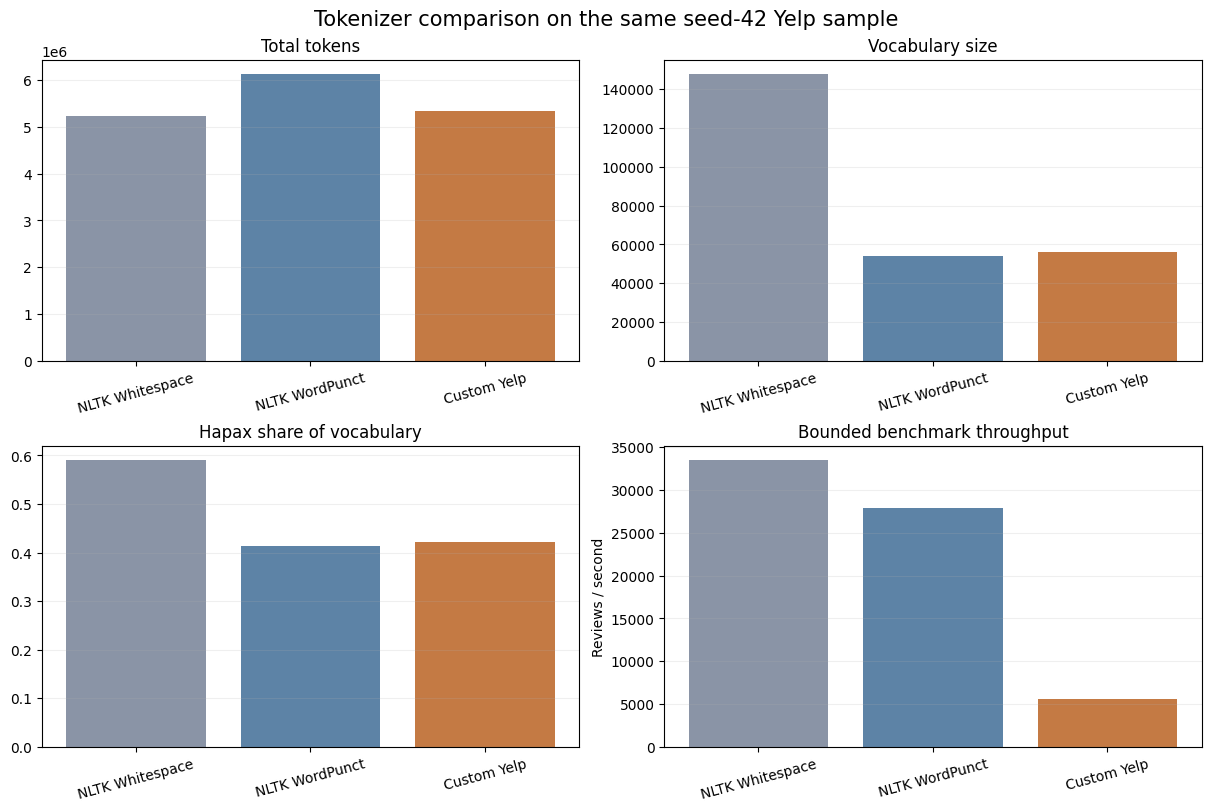

In [5]:
colors = ['#8A94A6', '#5D83A6', '#C47A44']
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
metrics = [
    ('tokens', 'Total tokens'),
    ('vocabulary', 'Vocabulary size'),
    ('hapax_share', 'Hapax share of vocabulary'),
]
for ax, (column, title) in zip(axes.flat[:3], metrics):
    ax.bar(summary['tokenizer'], summary[column], color=colors)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=.2)
axes.flat[3].bar(benchmark['tokenizer'], benchmark['median_reviews_per_second'], color=colors)
axes.flat[3].set_title('Bounded benchmark throughput')
axes.flat[3].set_ylabel('Reviews / second')
axes.flat[3].tick_params(axis='x', rotation=15)
axes.flat[3].grid(axis='y', alpha=.2)
fig.suptitle('Tokenizer comparison on the same seed-42 Yelp sample', fontsize=15)
fig.savefig(output_dir / 'tokenizer_comparison.png', dpi=220)
plt.show()

## Qualitative policy cases

These constructed examples illustrate boundary behavior; they are not annotated corpus accuracy. The custom rules intentionally preserve contractions, structured numbers, URLs, emoji sequences, hashtags, and emoticons.

In [6]:
cases = {
    'contractions': "Don't can't I'm we've y'all's didn't.",
    'hyphens': 'state-of-the-art the-best-food',
    'numbers': '12.50 1,234.50 $10 250$ 50¢ 10+ 20+% 29°F',
    'url': 'Visit https://my-site.com/menu?a=1&b=2!!!',
    'emoji': 'Good😂😂 👍🏽 👨‍👩‍👧‍👦 🇺🇸 1️⃣',
    'punctuation': 'Really?!!!! #deal #',
    'emoticons': ':) XD :D :( ;-) ^_^ o_o ¯\_(ツ)_/¯',
}
case_rows = []
for feature, text in cases.items():
    for name, tokenize in methods.items():
        case_rows.append({
            'feature': feature,
            'tokenizer': name,
            'tokens': json.dumps(tokenize(text), ensure_ascii=False),
        })
qualitative = pd.DataFrame(case_rows)
pd.set_option('display.max_colwidth', 180)
qualitative

<>:8: SyntaxWarning: invalid escape sequence '\_'
<>:8: SyntaxWarning: invalid escape sequence '\_'
C:\Users\Nick\AppData\Local\Temp\ipykernel_2572\1312473505.py:8: SyntaxWarning: invalid escape sequence '\_'
  'emoticons': ':) XD :D :( ;-) ^_^ o_o ¯\_(ツ)_/¯',


,feature,tokenizer,tokens
0,contractions,NLTK Whitespace,"[""don't"", ""can't"", ""i'm"", ""we've"", ""y'all's"", ""didn't.""]"
1,contractions,NLTK WordPunct,"[""don"", ""'"", ""t"", ""can"", ""'"", ""t"", ""i"", ""'"", ""m"", ""we"", ""'"", ""ve"", ""y"", ""'"", ""all"", ""'"", ""s"", ""didn"", ""'"", ""t"", "".""]"
2,contractions,Custom Yelp,"[""don't"", ""can't"", ""i'm"", ""we've"", ""y'all's"", ""didn't""]"
3,hyphens,NLTK Whitespace,"[""state-of-the-art"", ""the-best-food""]"
4,hyphens,NLTK WordPunct,"[""state"", ""-"", ""of"", ""-"", ""the"", ""-"", ""art"", ""the"", ""-"", ""best"", ""-"", ""food""]"
5,hyphens,Custom Yelp,"[""state"", ""of"", ""the"", ""art"", ""the"", ""best"", ""food""]"
6,numbers,NLTK Whitespace,"[""12.50"", ""1,234.50"", ""$10"", ""250$"", ""50¢"", ""10+"", ""20+%"", ""29°f""]"
7,numbers,NLTK WordPunct,"[""12"", ""."", ""50"", ""1"", "","", ""234"", ""."", ""50"", ""$"", ""10"", ""250"", ""$"", ""50"", ""¢"", ""10"", ""+"", ""20"", ""+%"", ""29"", ""°"", ""f""]"
8,numbers,Custom Yelp,"[""12.50"", ""1,234.50"", ""$10"", ""$250"", ""50¢"", ""10+"", ""20+%"", ""29°f""]"
9,url,NLTK Whitespace,"[""visit"", ""https://my-site.com/menu?a=1&b=2!!!""]"


In [ ]:
summary.to_csv(output_dir / 'summary.csv', index=False)
benchmark.to_csv(output_dir / 'runtime_benchmark.csv', index=False)
qualitative.to_csv(output_dir / 'qualitative_cases.csv', index=False)
run_metadata = {
    'config': str(CONFIG_PATH),
    'sample_path': str(sample_path),
    'sample_size': sample_size,
    'seed': seed,
    'normalization': 'RegexTokenizer.normalize applied to every method',
    'retention': 'all tokens; no stopword, stemming, lemmatization, or punctuation filter',
    'python': platform.python_version(),
    'nltk': nltk.__version__,
    'results': summary.to_dict(orient='records'),
    'benchmark': benchmark.to_dict(orient='records'),
}
(output_dir / 'summary.json').write_text(
    json.dumps(run_metadata, indent=2, ensure_ascii=False), encoding='utf-8'
)

custom_row = summary.set_index('tokenizer').loc['Custom Yelp']
wordpunct_row = summary.set_index('tokenizer').loc['NLTK WordPunct']
whitespace_row = summary.set_index('tokenizer').loc['NLTK Whitespace']